# MATH840 Final project, Session 1

Tuesday 3 November 2026. Submit `SURNAME_project.csv` on Moodle by **11:30**.

You work as a data scientist at an energy company. You have the hourly electricity generation of its
portfolio, with the weather, up to midnight on 27 October 2026. Your task is to forecast the next 48
hours, hour by hour, with a 95% prediction interval.

This notebook loads the data, defines the scores, computes the benchmark and writes the submission file.
You choose and build the model yourself.

The submission cell starts from the benchmark. If you run the notebook from top to bottom first, you
will have a valid file within five minutes, and you can use the rest of the session to beat it.

## 0. Setup

Download `train.csv` and `weather_forecast.csv` from Moodle. In Colab, the next cell asks you to upload
them. On your own machine, put them in the same folder as the notebook.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 120, "display.precision", 3)

SURNAME = "CHERVONETSKA"   # <-- for your submission file name

if not SURNAME.strip():
    raise ValueError("Set SURNAME before running the rest.")

In [2]:
NEEDED = ["train.csv", "weather_forecast.csv"]

if not all(Path(f).exists() for f in NEEDED):
    try:
        from google.colab import files
        files.upload()                       # choose both files at once
    except ImportError:
        raise FileNotFoundError(f"Put {NEEDED} next to this notebook.")

data = pd.read_csv("train.csv", parse_dates=["ds"])
weather_fc = pd.read_csv("weather_forecast.csv", parse_dates=["ds"])

H = 48                                       # hours to forecast
M = 24                                       # the benchmark's season: one day
FUTURE = weather_fc["ds"]

assert len(FUTURE) == H and FUTURE.iloc[0] == data["ds"].iloc[-1] + pd.Timedelta(hours=1)
print(f"history: {len(data)} hours, {data['ds'].min()} to {data['ds'].max()}")
print(f"you are forecasting: {FUTURE.iloc[0]} to {FUTURE.iloc[-1]}")
data.tail()

Saving weather_forecast.csv to weather_forecast.csv
Saving train.csv to train.csv
history: 33480 hours, 2023-01-01 01:00:00 to 2026-10-27 00:00:00
you are forecasting: 2026-10-27 01:00:00 to 2026-10-29 00:00:00


,ds,y,cloud_cover,temperature,wind_speed,pressure,humidity,daylight,air_density
33475,2026-10-26 20:00:00,42.5,1.0,9,3,763,87,0,1.259
33476,2026-10-26 21:00:00,76.7,1.0,9,4,763,87,0,1.259
33477,2026-10-26 22:00:00,65.8,1.0,7,3,763,100,0,1.268
33478,2026-10-26 23:00:00,69.9,1.0,7,3,763,100,0,1.268
33479,2026-10-27 00:00:00,69.9,1.0,7,3,763,100,0,1.268


### The data

| Column | Meaning |
|---|---|
| `ds` | the hour |
| `y` | electricity generated in that hour; this is what you forecast |
| `cloud_cover` | from 0 (clear) to 1 (overcast), in steps of 0.25 |
| `temperature` | °C |
| `wind_speed` | m/s |
| `pressure` | mm Hg |
| `humidity` | % |
| `daylight` | 1 while the sun is above the horizon |
| `air_density` | kg/m³ |

`train.csv` has the weather as it was. `weather_forecast.csv` has a forecast for the 48 hours you
predict, of the kind a weather service issues. Its errors grow from the first day to the second.

## 1. How you are scored

Your file gets three scores on the 48 hidden hours, and lower is better for each. RMSE measures the
point forecast in the units of `y`, and MAPE measures it in percent of the actual value. The Winkler
score measures the 95% interval: its width, plus 40 times ($2/\alpha$) the distance by which the actual
value falls outside it.

The benchmark is a seasonal naive forecast with a daily season. Each hour of the next two days gets the
value of the same hour on the last day you have. Its 95% interval is the standard one for seasonal naive,
$\hat y \pm 1.96\,\hat\sigma\sqrt{k+1}$, where $k$ is the number of full days into the horizon.

The project description on Moodle explains the points and the leaderboard.

In [3]:
def rmse(actual, forecast) -> float:
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(forecast)) ** 2)))


def mape(actual, forecast) -> float:
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    return float(np.mean(np.abs((actual - forecast) / actual)) * 100)


def winkler(actual, lower, upper, alpha: float = 0.05) -> float:
    actual, lower, upper = (np.asarray(a, float) for a in (actual, lower, upper))
    below = np.clip(lower - actual, 0, None)
    above = np.clip(actual - upper, 0, None)
    return float(np.mean((upper - lower) + 2 / alpha * (below + above)))


def score(actual, forecast, lower, upper) -> dict:
    inside = (np.asarray(actual) >= lower) & (np.asarray(actual) <= upper)
    return {"RMSE": rmse(actual, forecast), "MAPE": mape(actual, forecast),
            "Winkler": winkler(actual, lower, upper), "coverage": float(inside.mean())}


def snaive(history: np.ndarray, h: int = H, m: int = M):
    # The benchmark: repeat the last season, with the seasonal-naive 95% interval.
    history = np.asarray(history, float)
    point = np.array([history[-m + (i % m)] for i in range(h)])
    sigma = np.std(history[m:] - history[:-m], ddof=1)
    k = np.arange(h) // m
    half = 1.96 * sigma * np.sqrt(k + 1)
    return point, np.clip(point - half, 0, None), point + half

### The benchmark on a validation window

You cannot score a forecast on the hidden hours, so the cell below holds back the last 48 hours of the
history, forecasts them from the hours before, and scores the result. This is a single window. You can
decide how much more validation you need.

In [4]:
y = data["y"].to_numpy(float)
past, valid = y[:-H], y[-H:]

bench = snaive(past)
results = pd.DataFrame({"seasonal naive": score(valid, *bench)}).T
results

,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.0


## EDA

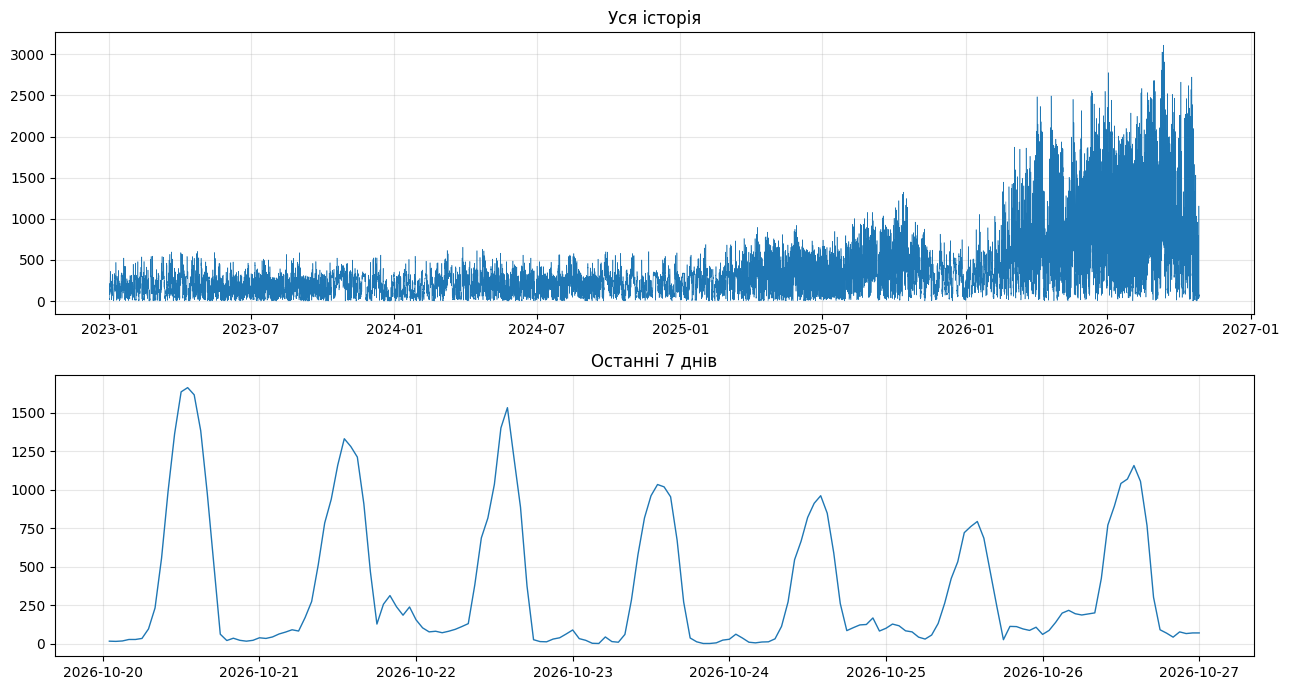

In [5]:
W = ["cloud_cover", "temperature", "wind_speed", "pressure", "humidity", "daylight", "air_density"]
y = data["y"].to_numpy(float)
n = len(data)

fig, ax = plt.subplots(2, 1, figsize=(13, 7))
ax[0].plot(data["ds"], y, lw=0.4); ax[0].set_title("Уся історія")
ax[1].plot(data["ds"].iloc[-7*M:], y[-7*M:], lw=1); ax[1].set_title("Останні 7 днів")
plt.tight_layout(); plt.show()

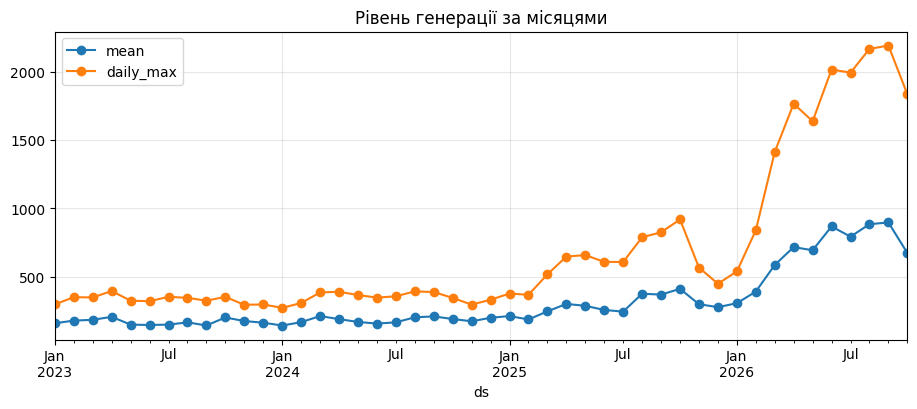

середнє за роками:
ds
2023    170.8
2024    183.9
2025    291.5
2026    683.8
Name: y, dtype: float64


In [6]:
s = data.set_index("ds")["y"]
lvl = pd.DataFrame({"mean": s.resample("MS").mean(),
                    "daily_max": s.resample("D").max().resample("MS").mean()})
lvl.plot(marker="o", title="Рівень генерації за місяцями")
plt.show()
print("середнє за роками:")
print(s.groupby(s.index.year).mean().round(1))

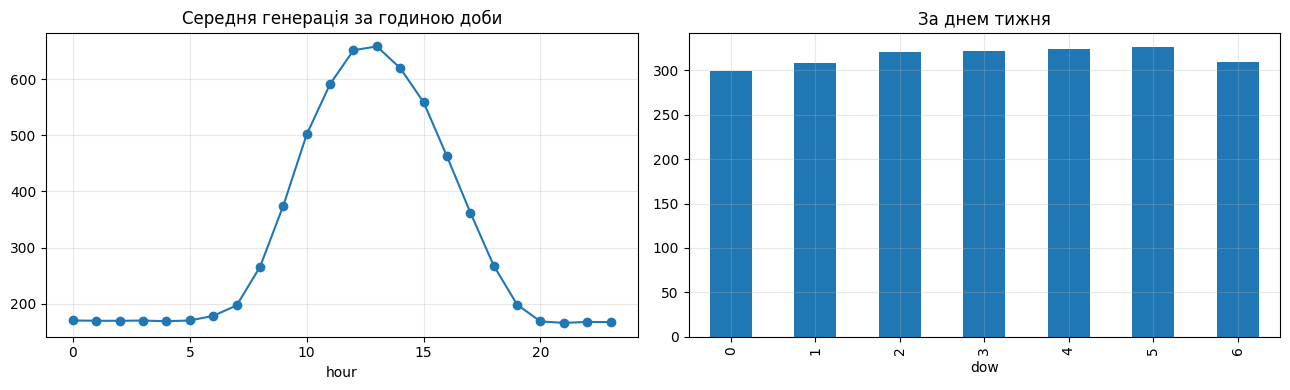

частка y == 0: 0.000;  y < 1: 0.004
ніч (daylight=0): {'count': 17589.0, 'mean': 174.2, 'std': 142.5, 'min': 0.7, '25%': 54.8, '50%': 139.7, '75%': 274.0, 'max': 1002.8}
день (daylight=1): {'count': 15891.0, 'mean': 472.5, 'std': 480.8, 'min': 0.7, '25%': 179.5, '50%': 315.1, '75%': 547.3, 'max': 3111.3}


In [7]:
data["hour"] = data["ds"].dt.hour
data["dow"] = data["ds"].dt.dayofweek
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
data.groupby("hour")["y"].mean().plot(marker="o", ax=ax[0], title="Середня генерація за годиною доби")
data.groupby("dow")["y"].mean().plot.bar(ax=ax[1], title="За днем тижня")
plt.tight_layout(); plt.show()

night = data[data["daylight"] == 0]["y"]; day = data[data["daylight"] == 1]["y"]
print(f"частка y == 0: {(y == 0).mean():.3f};  y < 1: {(y < 1).mean():.3f}")
print("ніч (daylight=0):", night.describe().round(1).to_dict())
print("день (daylight=1):", day.describe().round(1).to_dict())

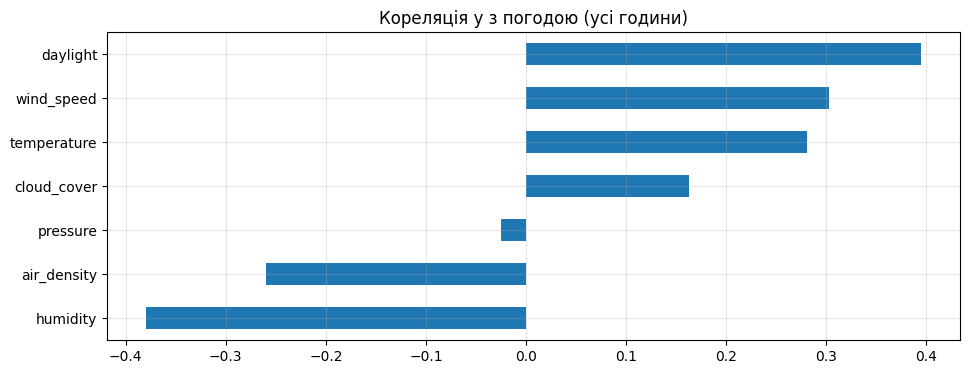

кореляція лише вдень:
humidity      -0.350
air_density   -0.246
pressure       0.019
wind_speed     0.174
cloud_cover    0.218
temperature    0.268
Name: y, dtype: float64


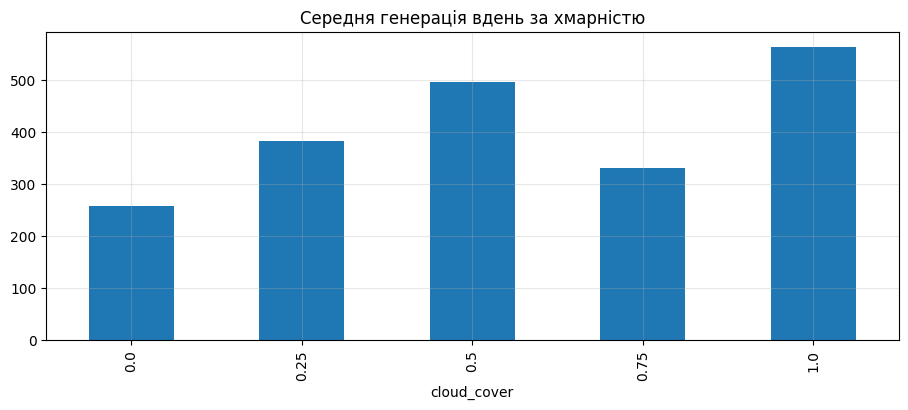

In [8]:
corr = data[["y"] + W].corr()["y"].drop("y").sort_values()
corr.plot.barh(title="Кореляція y з погодою (усі години)"); plt.show()

d = data[data["daylight"] == 1]
print("кореляція лише вдень:")
print(d[["y"] + W].corr()["y"].drop(["y", "daylight"]).sort_values().round(3))

d.groupby("cloud_cover")["y"].mean().plot.bar(title="Середня генерація вдень за хмарністю")
plt.show()

/tmp/ipykernel_925/164150901.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  print("ADF p (y):", round(adfuller(y, autolag="AIC")[1], 4), "| KPSS p (y):", round(kpss(y, nlags="auto")[1], 4))


ADF p (y): 0.0 | KPSS p (y): 0.01


/tmp/ipykernel_925/164150901.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  print("ADF p (різниця 24):", round(adfuller(z, autolag="AIC")[1], 4), "| KPSS p:", round(kpss(z, nlags="auto")[1], 4))


ADF p (різниця 24): 0.0 | KPSS p: 0.1


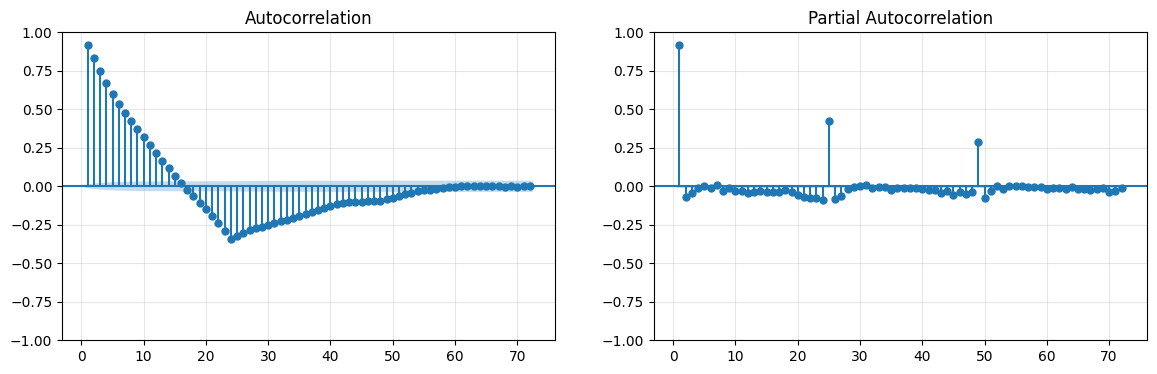

In [9]:
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

z = y[M:] - y[:-M]
print("ADF p (y):", round(adfuller(y, autolag="AIC")[1], 4), "| KPSS p (y):", round(kpss(y, nlags="auto")[1], 4))
print("ADF p (різниця 24):", round(adfuller(z, autolag="AIC")[1], 4), "| KPSS p:", round(kpss(z, nlags="auto")[1], 4))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(z, lags=72, ax=ax[0], zero=False); plot_pacf(z, lags=72, ax=ax[1], zero=False, method="ywm")
plt.show()

In [10]:
last7 = data.iloc[-7*M:]
cmp_ = pd.DataFrame({
    "останні 7 днів": last7[W].mean(),
    "прогноз, доба 1": weather_fc.iloc[:M][W].mean(),
    "прогноз, доба 2": weather_fc.iloc[M:][W].mean()})
print(cmp_.round(2))
print("\nmax y за останні 7 днів по добах:",
      pd.Series(y[-7*M:]).groupby(np.arange(7*M)//M).max().round(0).tolist())

             останні 7 днів  прогноз, доба 1  прогноз, доба 2
cloud_cover            0.29             0.97             0.26
temperature           10.80             6.75            11.33
wind_speed             2.01             3.00             2.12
pressure             763.29           762.96           758.04
humidity              91.83            99.00            92.67
daylight               0.38             0.38             0.38
air_density            1.25             1.27             1.25

max y за останні 7 днів по добах: [1662.0, 1330.0, 1532.0, 1033.0, 960.0, 793.0, 1156.0]


**Висновки EDA**

- **Рівень росте.** До 2025 року генерація стабільна (середнє ≈170–180, денний максимум ≈300–400). З 2025 року вона різко росте: у 2026 середнє ≈680, піки до 3000. Тому для навчання важливі передусім останні місяці.
- **Восени спад.** У жовтні 2026 рівень нижчий, ніж улітку. Такий самий провал був восени 2025, тож це, ймовірно, сезонність.
- **Сильний добовий цикл.** Мінімум уночі (≈170), пік о 13:00 (≈660). Ніч не нульова. Дні тижня майже не впливають.
- **Піки дуже різні.** За останній тиждень денний максимум скакав від ≈790 до ≈1660, тому повторити вчорашній день (snaive) — грубий прогноз.
- **Погода.** Генерація вища вдень, при вітрі й теплі, і нижча при високій вологості. Хмарність несподівано корелює додатно, тож це не чисто сонячна генерація, а частину зв'язку дає спільний ріст рівня.
- **Стаціонарність.** Сирий ряд нестаціонарний через зсув рівня. Після різниці з лагом 24 тести ADF і KPSS погоджуються, що він стаціонарний.
- **ACF/PACF.** Після різниці з лагом 24 PACF має піки на лагах 1, 25 і 49, тобто є сильна залежність від попередньої години і від тієї самої години вчора.
- **Горизонт.** За прогнозом погоди перша доба похмура й волога (хмарність 0,97), друга схожа на останній тиждень. Тож перша доба може відрізнятися від звичного профілю.

## 2. Your model

You can use any model or library, from the course or outside it, with or without the weather forecast.
Add your validation scores to `results`, so that they sit next to the benchmark's.

When you have chosen a model, fit it on the whole history and forecast the 48 hours after the end of
`data` in the submission cell below.

### Схема валідації

In [11]:
N_FOLDS = 10
ORIGINS = [n - H * (N_FOLDS - i) for i in range(N_FOLDS)]    # фолд 10 = останні 48 год історії
ACT = [y[o:o + H] for o in ORIGINS]
DL = [data["daylight"].to_numpy()[o:o + H] for o in ORIGINS]
print(pd.DataFrame({"origin": [data["ds"].iloc[o] for o in ORIGINS]}, index=range(1, N_FOLDS + 1)))

def cv_rmse(preds): return float(np.mean([rmse(a, p) for a, p in zip(ACT, preds)]))
def cv_mape(preds): return float(np.mean([mape(a, p) for a, p in zip(ACT, preds)]))
def fold_rmse(preds): return [rmse(a, p) for a, p in zip(ACT, preds)]
def avg(*ps): return [np.mean(x, axis=0) for x in zip(*ps)]

P = {"snaive": [snaive(y[:o])[0] for o in ORIGINS]}
print("snaive: RMSE", round(cv_rmse(P["snaive"]), 1), "MAPE", round(cv_mape(P["snaive"]), 1))

                origin
1  2026-10-07 01:00:00
2  2026-10-09 01:00:00
3  2026-10-11 01:00:00
4  2026-10-13 01:00:00
5  2026-10-15 01:00:00
6  2026-10-17 01:00:00
7  2026-10-19 01:00:00
8  2026-10-21 01:00:00
9  2026-10-23 01:00:00
10 2026-10-25 01:00:00
snaive: RMSE 281.4 MAPE 424.9


### Статистичні моделі: SARIMA

Кандидати з ACF/PACF: AR(1) і сезонна AR-частина з періодом 24 після сезонної різниці. Для порівняння також чистий сезонний AR, варіант із MA(1), варіант із сезонним MA і класична airline-модель. Кожна модель навчається на останніх 28 днях перед фолдом (на довшій історії SARIMA з періодом 24 рахується дуже повільно). Інтервал 95% беремо з самої моделі.

In [12]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
import time

SARIMA_SPECS = {
    "SAR (0,0,0)(1,1,0)":      ((0, 0, 0), (1, 1, 0, 24)),
    "AR+SAR (1,0,0)(1,1,0)":   ((1, 0, 0), (1, 1, 0, 24)),
    "ARMA+SAR (1,0,1)(1,1,0)": ((1, 0, 1), (1, 1, 0, 24)),
    "AR+SARMA (1,0,0)(1,1,1)": ((1, 0, 0), (1, 1, 1, 24)),
    "Airline (0,1,1)(0,1,1)":  ((0, 1, 1), (0, 1, 1, 24)),
}
WIN = 28 * M          # вікно навчання SARIMA: останні 28 днів

def sarima_fc(hist, order, sorder):
    m = SARIMAX(hist[-WIN:], order=order, seasonal_order=sorder,
                enforce_stationarity=False, enforce_invertibility=False)
    r = m.fit(disp=False, maxiter=100)
    f = r.get_forecast(H)
    ci = f.conf_int(alpha=0.05)
    p = np.maximum(f.predicted_mean, 0)
    return p, np.maximum(ci[:, 0], 0), np.maximum(ci[:, 1], p)

SAR_INT = {}
rows = {}
for name, (order, sorder) in SARIMA_SPECS.items():
    t = time.time()
    out = [sarima_fc(y[:o], order, sorder) for o in ORIGINS]
    P[name] = [o_[0] for o_ in out]
    SAR_INT[name] = out
    sc = pd.DataFrame([score(ACT[i], *out[i]) for i in range(N_FOLDS)]).mean()
    rows[name] = {"RMSE": sc["RMSE"], "MAPE": sc["MAPE"], "Winkler": sc["Winkler"],
                  "coverage": sc["coverage"], "сек": time.time() - t}

sn = pd.DataFrame([score(ACT[i], *snaive(y[:o])) for i, o in enumerate(ORIGINS)]).mean()
rows["snaive"] = {"RMSE": sn["RMSE"], "MAPE": sn["MAPE"], "Winkler": sn["Winkler"], "coverage": sn["coverage"]}
print(pd.DataFrame(rows).T.sort_values("RMSE").round(2))

print("\nRMSE по фолдах:")
print(pd.DataFrame({k: fold_rmse(P[k]) for k in ["snaive"] + list(SARIMA_SPECS)},
                   index=range(1, N_FOLDS + 1)).round(0))

                           RMSE    MAPE  Winkler  coverage    сек
ARMA+SAR (1,0,1)(1,1,0)  277.84  278.45  1195.95      0.97  22.18
SAR (0,0,0)(1,1,0)       278.94  636.02  1183.95      0.97  13.78
snaive                   281.45  424.86  2020.24      0.80    NaN
AR+SAR (1,0,0)(1,1,0)    284.01  247.77  1226.88      0.95  25.27
AR+SARMA (1,0,0)(1,1,1)  301.15  288.02  1338.53      0.92  75.68
Airline (0,1,1)(0,1,1)   347.05  267.11  1721.55      1.00  56.84

RMSE по фолдах:
    snaive  SAR (0,0,0)(1,1,0)  AR+SAR (1,0,0)(1,1,0)  ARMA+SAR (1,0,1)(1,1,0)  AR+SARMA (1,0,0)(1,1,1)  \
1    395.0               367.0                  422.0                    390.0                    318.0   
2    308.0               303.0                  358.0                    342.0                    322.0   
3    243.0               195.0                  205.0                    201.0                    174.0   
4    263.0               282.0                  284.0                    285.0               

**Висновки: SARIMA**

- **За RMSE SARIMA майже не краща за snaive.** Найкращі ARMA+SAR (278) і SAR (279) проти 281 у snaive, тобто різниця ≈1%. Вона менша за розкид між фолдами. Без погоди модель не знає, яким буде наступний пік, і по суті теж повторює вчорашній день.
- **За MAPE SARIMA помітно краща.** AR+SAR має 248, ARMA+SAR 278 проти 425 у snaive. Члени AR(1) і MA(1) згладжують прогноз уночі, де через малі значення MAPE найчутливіший. Виняток — чистий SAR без AR-частини (636).
- **Інтервали SARIMA кращі за шаблонний.** Winkler ≈1180–1230 проти 2020. Інтервал snaive зашироким не назвеш: він покриває лише 80% точок, а кожен промах дорого коштує.
- **Складніші моделі гірші й нестабільні.** Сезонний MA (SARMA) і Airline мають RMSE 301 і 347, а по фолдах скачуть від 91 до 592. Окремі фолди вони прогнозують дуже погано. До того ж вони рахуються найдовше.
- **Рішення.** Як точковий прогноз SARIMA бенчмарк не б'є, тож потрібна модель, яка використовує прогноз погоди. AR+SAR (1,0,0)(1,1,0) лишаємо як найкращу статистичну модель для порівняння.

### ML-моделі з погодою

SARIMA не бачить погоди, тому переходимо до регресії на фічах. Фічі: погода з прогнозу, година доби (sin/cos), «чисте сонце» (daylight × (1 − cloud_cover)) і дві фічі з історії, відомі на весь горизонт: значення 48 год тому та середнє за тиждень до цього. Порівнюємо лінійну модель (Ridge) і градієнтний бустинг (CatBoost) на трьох вікнах навчання: 30, 60 і 120 днів.

In [13]:
!pip install -q catboost

In [14]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from catboost import CatBoostRegressor

def make_features(df):
    F = df[W].copy()
    hour = df["ds"].dt.hour
    F["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    F["hour_cos"] = np.cos(2 * np.pi * hour / 24)
    F["sun_clear"] = df["daylight"] * (1 - df["cloud_cover"])
    s = df["y"]
    F["y_lag48"] = s.shift(48)                       # відомо для всього горизонту
    F["lvl_7d"] = s.shift(48).rolling(168).mean()    # рівень за тиждень
    return F

FEAT = make_features(data)
MIN_START = 168 + 48

def fit_predict(make_model, o, days=60, feat=None):
    feat = FEAT if feat is None else feat
    lo = max(o - days * M, MIN_START)
    m = make_model(); m.fit(feat.iloc[lo:o], y[lo:o])
    return np.maximum(m.predict(feat.iloc[o:o + H]), 0)

ridge = lambda: make_pipeline(StandardScaler(), Ridge(alpha=10))
cat = lambda seed=42: CatBoostRegressor(iterations=300, depth=5, learning_rate=0.05,
                                        l2_leaf_reg=5, verbose=False, random_seed=seed)

In [15]:
for d in (30, 60, 120):
    P[f"ridge_{d}d"] = [fit_predict(ridge, o, d) for o in ORIGINS]
    P[f"cat_{d}d"] = [fit_predict(cat, o, d) for o in ORIGINS]

show = ["snaive", "AR+SAR (1,0,0)(1,1,0)"] + [f"{m}_{d}d" for m in ("ridge", "cat") for d in (30, 60, 120)]
tab = pd.DataFrame({k: {"RMSE": cv_rmse(P[k]), "MAPE": cv_mape(P[k]),
                        "перемог над snaive": sum(a < b for a, b in zip(fold_rmse(P[k]), fold_rmse(P["snaive"])))}
                    for k in show}).T
print(tab.sort_values("RMSE").round(1))
P["cat_v1"] = P["cat_60d"]

                        RMSE   MAPE  перемог над snaive
cat_60d                241.3  504.8                 6.0
cat_30d                242.9  473.5                 6.0
cat_120d               248.3  530.6                 6.0
ridge_60d              271.7  635.1                 6.0
ridge_30d              276.7  562.9                 7.0
ridge_120d             277.5  675.0                 5.0
snaive                 281.4  424.9                 0.0
AR+SAR (1,0,0)(1,1,0)  284.0  247.8                 6.0


**Висновки: ML-моделі з погодою**

- **CatBoost найкращий за RMSE.** На всіх вікнах він дає 241–248 проти 281 у snaive, на 60 днях це ≈14% краще. Погода допомагає: SARIMA без неї майже не відрізнялася від snaive.
- **Ridge майже не краща за snaive.** RMSE 272–278, тобто виграш лише 1–3%. Лінійна модель не ловить нелінійний зв'язок генерації з погодою й годиною, тому Ridge відкидаємо.
- **Довжина вікна майже не впливає.** Для CatBoost різниця між 30, 60 і 120 днями ≈3%, і це менше за розкид між фолдами. Беремо 60 днів: достатньо коротке, щоб не тягнути старий нижчий рівень, і достатньо довге для стабільного навчання.
- **Перемога не в кожному фолді.** CatBoost кращий за snaive лише в 6 із 10 фолдів, тож середня перевага є, але окремий фолд може піти в будь-який бік.
- **За MAPE картина протилежна.** CatBoost (474–531) і Ridge (563–675) гірші за snaive (425) і значно гірші за SARIMA (248). Моделі зменшують великі помилки на піках, але завищують прогноз у години з малою генерацією, вночі. MAPE має 30% ваги в рейтингу, тому одного CatBoost замало. Далі пробуємо його покращити й поєднати з іншими моделями.

### CatBoost v3: прогноз на 48 год від точки прогнозу

У попередньому CatBoost фічі з історії відомі лише з лагом 48 год (`y_lag48`, `lvl_7d`). Тут інший підхід: для кожної точки прогнозу (раз на добу) беремо останні 168 год історії й будуємо з них фічі на весь горизонт. Це останнє значення, середні за 24/48/168 год, та сама година вчора й позавчора, максимум, мінімум і сума за останню добу. До них додаємо погоду, календар, крок горизонту (1–48) і взаємодії daylight×cloud, daylight×temp, wind². Модель навчається на всій історії.

In [16]:
def feats_v3(hist, fut):
    hist = np.asarray(hist, float)
    f = fut[["ds"] + W].copy().reset_index(drop=True)
    f["hour"] = f["ds"].dt.hour
    f["dayofweek"] = f["ds"].dt.dayofweek
    f["month"] = f["ds"].dt.month
    f["dayofyear"] = f["ds"].dt.dayofyear
    f["hour_sin"] = np.sin(2 * np.pi * f["hour"] / 24)
    f["hour_cos"] = np.cos(2 * np.pi * f["hour"] / 24)
    f["horizon"] = np.arange(1, len(f) + 1)
    f["last_y"] = hist[-1]
    f["last_24h_mean"] = hist[-24:].mean()
    f["last_24h_std"] = hist[-24:].std()
    f["last_48h_mean"] = hist[-48:].mean()
    f["last_168h_mean"] = hist[-168:].mean()
    idx = (f["horizon"].to_numpy() - 1) % 24
    f["prev_day_same_hour"] = hist[-24:][idx]
    f["prev_2day_same_hour"] = hist[-48:-24][idx]
    f["daily_change"] = f["prev_day_same_hour"] - f["prev_2day_same_hour"]
    f["last_day_max"] = hist[-24:].max()
    f["last_day_min"] = hist[-24:].min()
    f["last_day_energy"] = hist[-24:].sum()
    f["daylight_x_cloud"] = f["daylight"] * f["cloud_cover"]
    f["daylight_x_temp"] = f["daylight"] * f["temperature"]
    f["wind_squared"] = f["wind_speed"] ** 2
    return f.drop(columns="ds")

def train_set_v3(end, step=24):
    X, Y = [], []
    for o in range(168, end - H + 1, step):
        X.append(feats_v3(y[o - 168:o], data.iloc[o:o + H]))
        Y.append(y[o:o + H])
    return pd.concat(X, ignore_index=True), np.concatenate(Y)

def cat_v3(end, fut):
    X, Y = train_set_v3(end)
    m = CatBoostRegressor(iterations=700, depth=6, learning_rate=0.05, l2_leaf_reg=5,
                          random_seed=42, verbose=False, thread_count=-1)
    m.fit(X, Y)
    return np.maximum(m.predict(feats_v3(y[end - 168:end], fut)), 0)

P["cat_v3"] = []
for i, o in enumerate(ORIGINS):
    P["cat_v3"].append(cat_v3(o, data.iloc[o:o + H]))
    print(f"фолд {i+1}: RMSE {rmse(ACT[i], P['cat_v3'][-1]):.0f}")

show = ["snaive", "AR+SAR (1,0,0)(1,1,0)", "cat_60d", "cat_v3"]
sn = fold_rmse(P["snaive"])
print(pd.DataFrame({k: {"RMSE": cv_rmse(P[k]), "MAPE": cv_mape(P[k]),
                        "перемог над snaive": sum(a < b for a, b in zip(fold_rmse(P[k]), sn))}
                    for k in show}).T.sort_values("RMSE").round(1))
print("\nRMSE по фолдах:")
print(pd.DataFrame({k: fold_rmse(P[k]) for k in show}, index=range(1, N_FOLDS + 1)).round(0))

фолд 1: RMSE 357
фолд 2: RMSE 258
фолд 3: RMSE 164
фолд 4: RMSE 218
фолд 5: RMSE 226
фолд 6: RMSE 243
фолд 7: RMSE 263
фолд 8: RMSE 228
фолд 9: RMSE 118
фолд 10: RMSE 115
                        RMSE   MAPE  перемог над snaive
cat_v3                 219.0  278.5                 9.0
cat_60d                241.3  504.8                 6.0
snaive                 281.4  424.9                 0.0
AR+SAR (1,0,0)(1,1,0)  284.0  247.8                 6.0

RMSE по фолдах:
    snaive  AR+SAR (1,0,0)(1,1,0)  cat_60d  cat_v3
1    395.0                  422.0    224.0   357.0
2    308.0                  358.0    338.0   258.0
3    243.0                  205.0    208.0   164.0
4    263.0                  284.0    235.0   218.0
5    389.0                  371.0    274.0   226.0
6    430.0                  411.0    286.0   243.0
7    283.0                  246.0    296.0   263.0
8    202.0                  252.0    210.0   228.0
9    181.0                  173.0    135.0   118.0
10   120.0            

**Висновки: CatBoost v3**

- **Найкраща модель за RMSE.** У середньому 219 проти 281 у snaive, тобто на ≈22% краще. Попередній CatBoost давав 241.
- **Стабільніша за snaive.** CatBoost v3 кращий за snaive у 9 із 10 фолдів (раніше в 6). Програє лише у фолді 8 (228 проти 202). В останніх, спокійних фолдах (9 і 10) він теж кращий, хоча cat_60d там помітно програвав.
- **MAPE різко впав.** 278 проти 505 у cat_60d і 425 у snaive, тобто майже на рівні SARIMA (248). Фічі з останньої доби (мінімум, та сама година вчора) дають моделі знати, що вночі генерація низька, і вона перестає завищувати нічні години.
- **Слабке місце — окремі фолди.** У фолді 1 CatBoost v3 значно гірший за cat_60d (357 проти 224). Модель спирається на останню добу і помиляється, коли наступний день різко інший.
- **Рішення.** CatBoost v3 беремо як основну модель. Саме його подано в сесії 1.

### Ансамбль CatBoost v3 + snaive

CatBoost v3 і snaive помиляються в різні боки: модель згладжує й часто занижує пік, а snaive повторює вчорашній пік. Тому будуємо ансамбль як зважене середнє `(1 − w)·CatBoost v3 + w·snaive`. Спершу дивимося, як ансамбль працює на фолдах для різних `w`. Потім визначаємо вагу з публічного рейтингу: на першій прихованій добі RMSE CatBoost v3 ≈ 122, snaive ≈ 115. Для двох прогнозів F і S з відомими RMSE помилка ансамблю рахується точно:

RMSE²(w) = (1 − w)·RMSE²_F + w·RMSE²_S − w(1 − w)·mean((F − S)²),

звідки w* = (D + RMSE²_F − RMSE²_S) / (2D), де D = mean((F − S)²) на першій добі.

In [17]:
sn = fold_rmse(P["snaive"])
rows = {}
for w_ in (0, 0.25, 0.4, 0.5, 0.6, 0.75, 1):
    ens = [(1 - w_) * c + w_ * s for c, s in zip(P["cat_v3"], P["snaive"])]
    rows[w_] = {"RMSE": cv_rmse(ens), "MAPE": cv_mape(ens),
                "перемог над snaive": sum(a < b for a, b in zip(fold_rmse(ens), sn))}
print(pd.DataFrame(rows).T.round(1))

       RMSE   MAPE  перемог над snaive
0.00  219.0  278.5                 9.0
0.25  220.3  311.0                 9.0
0.40  226.2  331.3                10.0
0.50  232.1  345.2                10.0
0.60  239.5  359.5                10.0
0.75  253.1  381.8                10.0
1.00  281.4  424.9                 0.0


In [19]:
RMSE_CAT, RMSE_SN = 122.2, 115.7

F = cat_v3(n, weather_fc)
S = snaive(y)[0]

D = np.mean((F[:M] - S[:M]) ** 2)
rm = lambda w_: np.sqrt((1 - w_) * RMSE_CAT**2 + w_ * RMSE_SN**2 - w_ * (1 - w_) * D)
w = float(np.clip((D + RMSE_CAT**2 - RMSE_SN**2) / (2 * D), 0, 1))
print(f"w = {w:.2f} | очікуваний RMSE на першій добі: CatBoost {RMSE_CAT}, snaive {RMSE_SN}, "
      f"ансамбль 50/50 {rm(0.5):.1f}, ансамбль з w {rm(w):.1f}")

forecast = (1 - w) * F + w * S
P["ensemble"] = [(1 - w) * c + w * s for c, s in zip(P["cat_v3"], P["snaive"])]

show = ["snaive", "AR+SAR (1,0,0)(1,1,0)", "cat_60d", "cat_v3", "ensemble"]
print(pd.DataFrame({k: {"RMSE": cv_rmse(P[k]), "MAPE": cv_mape(P[k]),
                        "перемог над snaive": sum(a < b for a, b in zip(fold_rmse(P[k]), sn))}
                    for k in show}).T.sort_values("RMSE").round(1))

w = 0.52 | очікуваний RMSE на першій добі: CatBoost 122.2, snaive 115.7, ансамбль 50/50 66.6, ансамбль з w 66.5
                        RMSE   MAPE  перемог над snaive
cat_v3                 219.0  278.5                 9.0
ensemble               233.5  348.0                10.0
cat_60d                241.3  504.8                 6.0
snaive                 281.4  424.9                 0.0
AR+SAR (1,0,0)(1,1,0)  284.0  247.8                 6.0


**Висновки: ансамбль CatBoost v3 + snaive**

- **Вага.** З публічних RMSE першої доби (CatBoost 122,2, snaive 115,7) оптимальна вага snaive w = 0,52, тобто майже рівні ваги. Очікуваний RMSE ансамблю на першій добі ≈66,5, майже вдвічі менше за кожну модель. Так виходить, бо моделі помилялися в протилежні боки: CatBoost занизив пік похмурого дня, snaive його завищив.
- **На фолдах ансамбль поступається CatBoost v3 за середнім** (RMSE 233,5 проти 219, MAPE 348 проти 279), зате він єдиний кращий за snaive в усіх 10 фолдах.
- **Чому обираємо ансамбль.** На фолдах CatBoost бачить фактичну погоду, а на горизонті лише прогноз, який помиляється сильніше на другу добу. Тому фолди завищують перевагу CatBoost. snaive погоди не використовує і страхує від цих помилок.

### Інтервал 95%

In [20]:
def vol(h, Dd=14):
    d = np.asarray(h, float)[-(Dd + 1) * M:]
    diff = (d[M:] - d[:-M]).reshape(Dd, M)
    g = np.sqrt(np.mean(diff ** 2))
    s = np.sqrt(np.mean(diff ** 2, axis=0))
    s = (np.roll(s, 1) + s + np.roll(s, -1)) / 3
    return np.tile(0.5 * s + 0.5 * g, 2)

def band(p, s, z):
    lo = np.maximum(p + min(np.quantile(z, .025), 0) * s, 0)
    up = p + max(np.quantile(z, .975), 0) * s
    return np.minimum(lo, p), np.maximum(up, p)

PE = P["ensemble"]
SC = [vol(y[:o]) for o in ORIGINS]
Z = [(a - p) / s for a, p, s in zip(ACT, PE, SC)]

rows = []
for i, o in enumerate(ORIGINS):
    rest = [j for j in range(N_FOLDS) if j != i]
    # сталий ±q95 (як у сесії 1)
    q = np.quantile(np.concatenate([np.abs(ACT[j] - PE[j]) for j in rest]), 0.95)
    c = score(ACT[i], PE[i], np.maximum(PE[i] - q, 0), PE[i] + q)
    # адаптивний
    lo, up = band(PE[i], SC[i], np.concatenate([Z[j] for j in rest]))
    a = score(ACT[i], PE[i], lo, up)
    # шаблон snaive
    sn_ = score(ACT[i], *snaive(y[:o]))
    rows.append({"Winkler snaive": sn_["Winkler"], "Winkler сталий": c["Winkler"], "Winkler адаптивний": a["Winkler"],
                 "покр. snaive": sn_["coverage"], "покр. сталий": c["coverage"], "покр. адаптивний": a["coverage"]})
R = pd.DataFrame(rows, index=range(1, N_FOLDS + 1))
print(R.round(2))
print("\nсереднє:"); print(R.mean().round(3))

lower_95, upper_95 = band(forecast, vol(y), np.concatenate(Z))
print("\nсередня ширина на горизонті: адаптивний", round(np.mean(upper_95 - lower_95)),
      "| шаблон", round(np.mean(snaive(y)[2] - snaive(y)[1])))

    Winkler snaive  Winkler сталий  Winkler адаптивний  покр. snaive  покр. сталий  покр. адаптивний
1          3982.89         1920.81             2531.27          0.62          0.90              0.79
2          1911.65         1067.36             1092.48          0.77          0.94              1.00
3          1661.70         1065.34             1181.55          0.88          0.96              0.96
4          1045.32          986.09             1039.64          0.79          1.00              1.00
5          3211.34         1384.29             1668.25          0.77          0.85              0.88
6          4134.61         1376.26             1844.00          0.62          0.90              0.85
7          1798.45          938.65             1066.27          0.79          0.94              0.90
8           992.16          857.55              895.75          0.88          0.98              0.98
9           895.81          819.61              776.38          0.92          1.00         

In [22]:
rows = []
for i, o in enumerate(ORIGINS):
    rest = [j for j in range(N_FOLDS) if j != i]
    q = np.quantile(np.concatenate([np.abs(ACT[j] - PE[j]) for j in rest]), 0.95)
    lo_c, up_c = np.maximum(PE[i] - q, 0), PE[i] + q
    lo_a, up_a = band(PE[i], SC[i], np.concatenate([Z[j] for j in rest]))
    lo_h, up_h = 0.5 * (lo_c + lo_a), 0.5 * (up_c + up_a)
    rows.append({"сталий": winkler(ACT[i], lo_c, up_c), "адаптивний": winkler(ACT[i], lo_a, up_a),
                 "середній": winkler(ACT[i], lo_h, up_h),
                 "покр. середній": np.mean((ACT[i] >= lo_h) & (ACT[i] <= up_h))})
R2 = pd.DataFrame(rows, index=range(1, N_FOLDS + 1))
print(R2.round(2)); print("\nсереднє:"); print(R2.mean().round(3))

q_all = np.quantile(np.concatenate([np.abs(a - p) for a, p in zip(ACT, PE)]), 0.95)
lo_c, up_c = np.maximum(forecast - q_all, 0), forecast + q_all
lo_a, up_a = band(forecast, vol(y), np.concatenate(Z))
print("\nширина на горизонті: сталий", round(np.mean(up_c - lo_c)), "| адаптивний", round(np.mean(up_a - lo_a)),
      "| середній", round(np.mean(0.5 * (up_c + up_a) - 0.5 * (lo_c + lo_a))),
      "| шаблон", round(np.mean(snaive(y)[2] - snaive(y)[1])))

     сталий  адаптивний  середній  покр. середній
1   1920.81     2531.27   2186.11            0.83
2   1067.36     1092.48   1037.56            1.00
3   1065.34     1181.55   1123.45            0.96
4    986.09     1039.64   1012.87            1.00
5   1384.29     1668.25   1505.55            0.83
6   1376.26     1844.00   1608.16            0.88
7    938.65     1066.27    986.28            0.94
8    857.55      895.75    876.65            0.98
9    819.61      776.38    775.98            1.00
10   796.96      683.56    740.26            1.00

середнє:
сталий            1121.294
адаптивний        1277.915
середній          1185.287
покр. середній       0.942
dtype: float64

ширина на горизонті: сталий 802 | адаптивний 640 | середній 721 | шаблон 609


**Висновки: інтервал 95%**

- **На фолдах найкращий сталий інтервал** ±q95 (Winkler 1121, покриття 0,946). Адаптивний гірший (1278): він звужується у спокійні періоди й провалюється, коли наступний день різко інший (фолди 1, 5, 6).
- **У спокійних фолдах 9–10, найближчих до горизонту, ситуація протилежна.** Адаптивний і середній кращі за сталий, а сталий у фолді 10 програє навіть шаблону. Те саме показав публічний рейтинг: сталий інтервал сесії 1 покрив 100% точок, але Winkler 715 проти 521 у snaive. Інтервал був зашироким.
- **Вибір: середнє сталого й адаптивного інтервалів.** На фолдах Winkler 1185 (≈6% гірше за сталий), покриття 0,942. На горизонті середня ширина 721 замість 802. Компроміс між надійністю на неспокійних днях і шириною на спокійних. Друга доба за прогнозом погоди схожа на останній тиждень, тобто, ймовірно, спокійна.

In [23]:
lower_95 = 0.5 * (lo_c + lo_a)
upper_95 = 0.5 * (up_c + up_a)
lower_95, upper_95 = np.minimum(lower_95, forecast), np.maximum(upper_95, forecast)
print("середня ширина:", round(np.mean(upper_95 - lower_95)))

середня ширина: 721


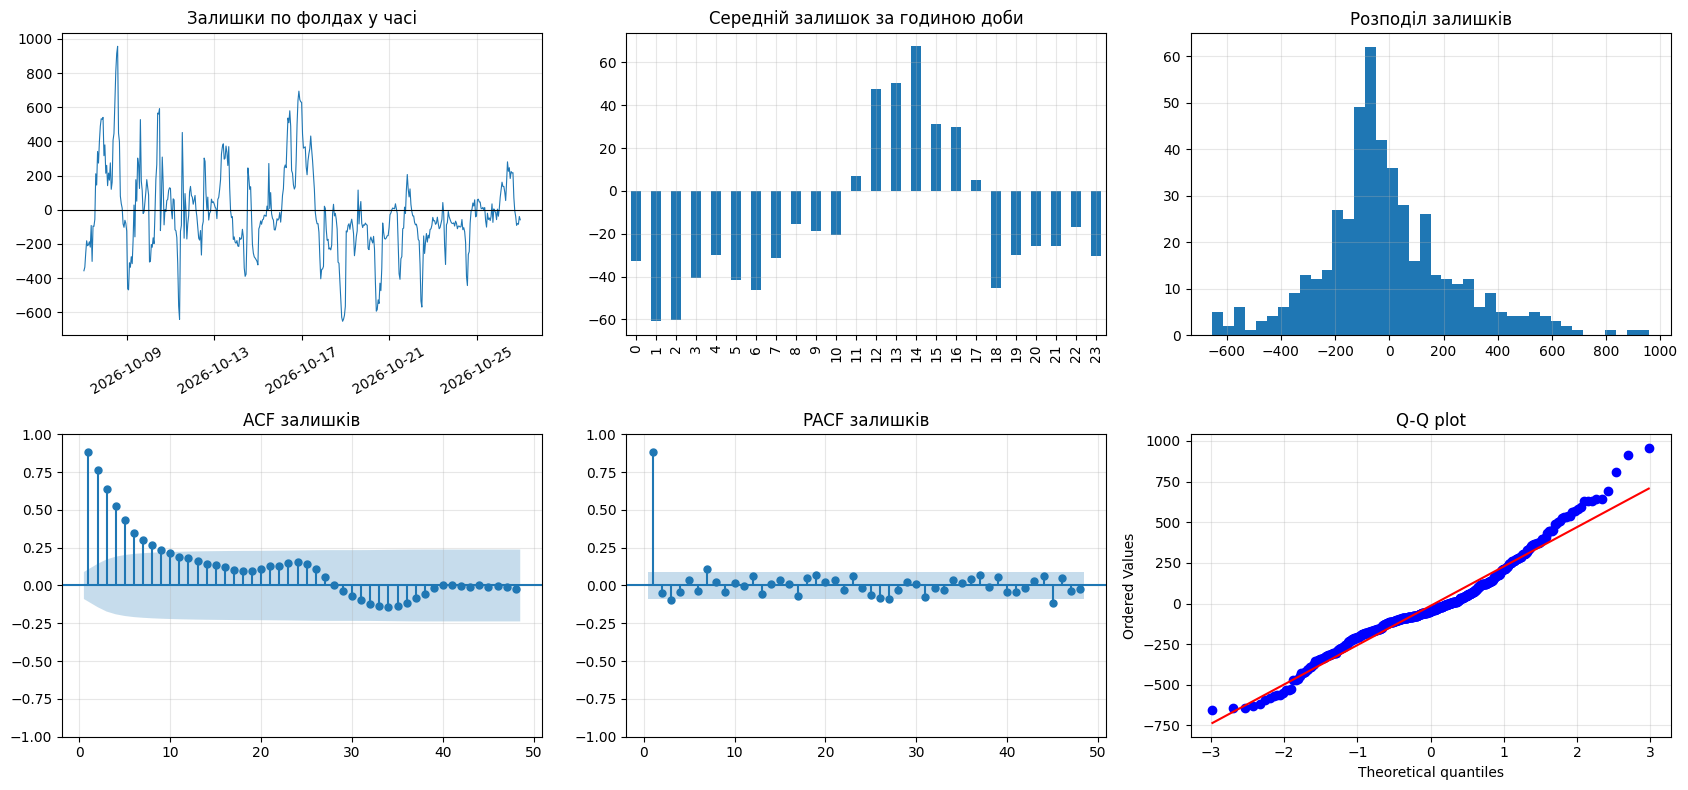

середній залишок (факт - прогноз): -13.9 | std: 245.2
залишок, день / ніч: 19.8 / -36.4
RMSE доба 1 / доба 2: 203.1 / 281.6

Ljung-Box:
     lb_stat  lb_pvalue
1    373.815        0.0
24  1402.085        0.0
48  1478.182        0.0


In [24]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy import stats

res = np.concatenate([a - p for a, p in zip(ACT, PE)])            # факт - прогноз
ds_cv = np.concatenate([data["ds"].iloc[o:o + H].to_numpy() for o in ORIGINS])
hrs = pd.to_datetime(ds_cv).hour
dayidx = np.tile(np.arange(H) // M, N_FOLDS)
dl_all = np.concatenate(DL)

fig, ax = plt.subplots(2, 3, figsize=(17, 8))
ax[0, 0].plot(ds_cv, res, lw=0.8); ax[0, 0].axhline(0, color="k", lw=0.8)
ax[0, 0].set_title("Залишки по фолдах у часі"); ax[0, 0].tick_params(axis="x", rotation=30)
pd.Series(res).groupby(hrs).mean().plot.bar(ax=ax[0, 1], title="Середній залишок за годиною доби")
ax[0, 2].hist(res, bins=40); ax[0, 2].set_title("Розподіл залишків")
plot_acf(res, lags=48, ax=ax[1, 0], zero=False, title="ACF залишків")
plot_pacf(res, lags=48, ax=ax[1, 1], zero=False, method="ywm", title="PACF залишків")
stats.probplot(res, dist="norm", plot=ax[1, 2]); ax[1, 2].set_title("Q-Q plot")
plt.tight_layout(); plt.show()

print("середній залишок (факт - прогноз):", round(res.mean(), 1), "| std:", round(res.std(), 1))
print("залишок, день / ніч:", round(res[dl_all == 1].mean(), 1), "/", round(res[dl_all == 0].mean(), 1))
print("RMSE доба 1 / доба 2:", round(rmse(0, res[dayidx == 0]), 1), "/", round(rmse(0, res[dayidx == 1]), 1))
print("\nLjung-Box:")
print(acorr_ljungbox(res, lags=[1, 24, 48]).round(4))

**Висновки: залишки ансамблю**

- **У часі.** Найбільші помилки в перших фолдах (до +950 біля 8 жовтня, до +690 біля 16 жовтня), коли пік виявився набагато вищим за прогноз. Біля 18–20 жовтня є довгі від'ємні ділянки до −650. В останніх фолдах (21–27 жовтня) залишки здебільшого в межах ±300, тобто останній період спокійніший.
- **За годинами.** Уночі й увечері (0–10 і 17–23 год) середній залишок від'ємний (−15…−60): ансамбль трохи завищує низькі значення. Вдень (12–16 год) він додатний (+30…+67): пік занижено. Систематичний зсув відносно малий порівняно з розкидом помилок (±200–600).
- **Розподіл.** Центр трохи нижче нуля (мода ≈ −80), правий хвіст довший (до +950), ніж лівий (до −650). Q-Q plot підтверджує: в правому хвості помилки більші, ніж у нормальному розподілі. Великі промахи — це передусім недооцінені високі піки. Тому межі інтервалу беремо з емпіричних квантилів, а не з нормального розподілу.
- **Автокореляція.** ACF на лагу 1 ≈ 0,88 і повільно спадає, значуща приблизно до лагу 10. PACF має лише один значущий пік, на лагу 1. Помилки не випадкові, а йдуть блоками годин, як AR(1): якщо модель помилилась уранці, вона, ймовірно, помилиться і далі протягом дня. Ljung-Box відкидає гіпотезу про білий шум.
- **Що це означає.** Під час прогнозу на 48 год ми не знаємо фактичних значень горизонту, тому цю автокореляцію не можна використати для корекції. Для інтервалу це означає, що промахи, якщо будуть, прийдуть кількома годинами поспіль, і покриття на конкретній добі може сильно відрізнятися від середніх 0,94.

- **Зміщення мале.** Середній залишок −13,9 при std 245: ансамбль у середньому майже не зсунутий. Уночі він завищує (−36,4), вдень трохи занижує (+19,8).
- **Друга доба помітно гірша.** RMSE 203 на першій добі горизонту проти 282 на другій. Чим далі від точки прогнозу, тим менше допомагає інформація з останньої доби. Тому на другу добу інтервал мав би бути ширшим.
- **Автокореляція.** ACF на лагу 1 ≈ 0,88 і повільно спадає, значуща приблизно до лагу 10. PACF має лише один значущий пік, на лагу 1. Ljung-Box відкидає білий шум на лагах 1, 24 і 48 (p ≈ 0). Помилки йдуть блоками годин, як AR(1).

## 3. Submission

Replace the benchmark in the first line with your own forecast. `forecast`, `lower_95` and `upper_95`
are arrays of 48 numbers, one for each hour in `FUTURE`, in order. Generation cannot be negative, so the
lower bound must be 0 or above.

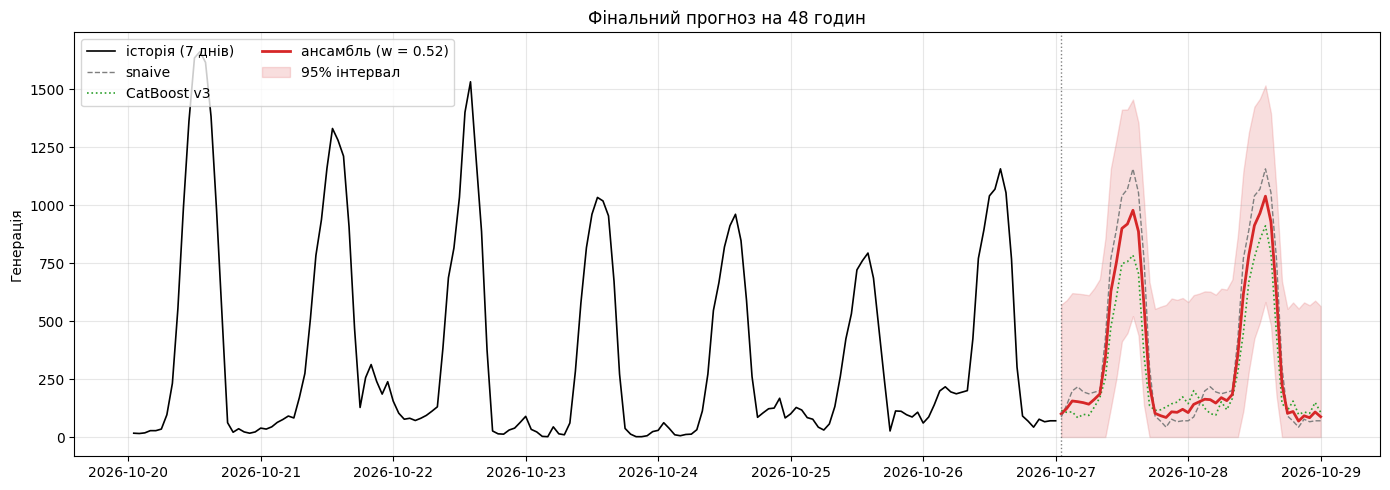

середня ширина інтервалу: 721


In [26]:
# фінальний прогноз: ансамбль CatBoost v3 + snaive, інтервал = середнє сталого й адаптивного
forecast = (1 - w) * F + w * S

q_all = np.quantile(np.concatenate([np.abs(a - p) for a, p in zip(ACT, PE)]), 0.95)
lo_c, up_c = np.maximum(forecast - q_all, 0), forecast + q_all
lo_a, up_a = band(forecast, vol(y), np.concatenate(Z))
lower_95 = np.minimum(0.5 * (lo_c + lo_a), forecast)
upper_95 = np.maximum(0.5 * (up_c + up_a), forecast)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(data["ds"].iloc[-7 * M:], y[-7 * M:], color="black", lw=1.2, label="історія (7 днів)")
ax.plot(FUTURE, S, color="tab:gray", ls="--", lw=1, label="snaive")
ax.plot(FUTURE, F, color="tab:green", ls=":", lw=1.2, label="CatBoost v3")
ax.plot(FUTURE, forecast, color="tab:red", lw=2, label=f"ансамбль (w = {w:.2f})")
ax.fill_between(FUTURE, lower_95, upper_95, color="tab:red", alpha=0.15, label="95% інтервал")
ax.axvline(FUTURE.iloc[0], color="gray", ls=":", lw=1)
ax.set_title("Фінальний прогноз на 48 годин"); ax.set_ylabel("Генерація")
ax.legend(ncol=2, loc="upper left")
plt.tight_layout(); plt.show()

print("середня ширина інтервалу:", round(np.mean(upper_95 - lower_95)))

In [27]:
def check_submission(sub: pd.DataFrame) -> None:
    assert list(sub.columns) == ["ds", "forecast", "lower_95", "upper_95"], "wrong columns"
    assert len(sub) == H, f"need {H} rows, got {len(sub)}"
    assert (pd.to_datetime(sub["ds"]).to_numpy() == FUTURE.to_numpy()).all(), "the hours do not match FUTURE"
    assert sub[["forecast", "lower_95", "upper_95"]].notna().all().all(), "missing values"
    assert (sub["lower_95"] >= 0).all(), "a lower bound is negative"
    assert (sub["lower_95"] <= sub["forecast"]).all() and (sub["forecast"] <= sub["upper_95"]).all(), \
        "the forecast must lie inside its interval"
    print("format OK")


submission = pd.DataFrame({"ds": FUTURE.dt.strftime("%Y-%m-%d %H:%M:%S"), "forecast": forecast,
                           "lower_95": lower_95, "upper_95": upper_95})
check_submission(submission)

FILE = f"{SURNAME.strip().upper()}_project.csv"
submission.to_csv(FILE, index=False)
print("saved", FILE)

try:
    from google.colab import files
    files.download(FILE)
except ImportError:
    pass

format OK
saved CHERVONETSKA_project.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Upload `SURNAME_project.csv` to the *Session 1* activity on Moodle by **11:30**. You can upload more than
once, and the last file before 11:30 counts, so submit the benchmark early and replace it if you find
something better.

After the session you can keep working on the forecast at home. The project description on Moodle has
the details.